# Real-World Dataset Analysis: Titanic Passengers
**Dataset:** Titanic passenger records (891 passengers), from the `seaborn-data` repository on GitHub (derived from the widely used Kaggle Titanic training set).
**Context:** The RMS Titanic sank on 15 April 1912. The dataset records who was on board and whether each passenger survived.
**Analytical objective:** Which passenger characteristics (sex, ticket class, age, family, fare) were associated with survival?
**Expected outcome:** A clear, evidence-based picture of the survival factors, plus recommendations on how such a model/analysis could be used.

## 1. Load and explore

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
sns.set_theme(style='whitegrid')
OR, GR = '#C2410C', '#6B7280'
raw = pd.read_csv('titanic.csv')
print('Shape:', raw.shape)
raw.head()

Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [3]:
print(raw.describe().round(2))
print()
print(raw.describe(include='str').T)

       survived  pclass     age   sibsp   parch    fare
count    891.00  891.00  714.00  891.00  891.00  891.00
mean       0.38    2.31   29.70    0.52    0.38   32.20
std        0.49    0.84   14.53    1.10    0.81   49.69
min        0.00    1.00    0.42    0.00    0.00    0.00
25%        0.00    2.00   20.12    0.00    0.00    7.91
50%        0.00    3.00   28.00    0.00    0.00   14.45
75%        1.00    3.00   38.00    1.00    0.00   31.00
max        1.00    3.00   80.00    8.00    6.00  512.33

            count unique          top freq
sex           891      2         male  577
embarked      889      3            S  644
class         891      3        Third  491
who           891      3          man  537
deck          203      7            C   59
embark_town   889      3  Southampton  644
alive         891      2           no  549


In [4]:
print('Missing values:'); print(raw.isna().sum()[raw.isna().sum()>0])
print('\nMissing %:'); print((raw.isna().mean()*100).round(1)[raw.isna().sum()>0])
print('\nExact duplicate rows:', raw.duplicated().sum())

Missing values:
age            177
embarked         2
deck           688
embark_town      2
dtype: int64

Missing %:
age            19.9
embarked        0.2
deck           77.2
embark_town     0.2
dtype: float64

Exact duplicate rows: 107


## 2. Clean and preprocess

In [5]:
d = raw.copy()
# a) Redundant columns: 'alive' repeats 'survived', 'class' repeats 'pclass', 'embarked' repeats 'embark_town'
print('alive == survived:', (d['alive'].eq('yes') == d['survived'].astype(bool)).all())
print('class == pclass  :', (d['class'].astype(str).map({'First':1,'Second':2,'Third':3}) == d['pclass']).all())
d = d.drop(columns=['alive','class','embarked'])
# b) Deck is 77% missing: keep only a flag instead of imputing
d['has_cabin_info'] = d['deck'].notna()
d = d.drop(columns='deck')
# c) Missing embark_town (2 rows): fill with mode
d['embark_town'] = d['embark_town'].fillna(d['embark_town'].mode()[0])
# d) Missing age: median by sex and class
d['age_was_missing'] = d['age'].isna()
d['age'] = d['age'].fillna(d.groupby(['sex','pclass'])['age'].transform('median'))
# e) Data types
d['pclass'] = d['pclass'].astype('category')
d['survived'] = d['survived'].astype(int)
for c in ['sex','embark_town','who']: d[c] = d[c].astype('category')
print('Missing values left:', int(d.isna().sum().sum()))
print(d.dtypes)

alive == survived: True
class == pclass  : True
Missing values left: 0
survived              int64
pclass             category
sex                category
age                 float64
sibsp                 int64
parch                 int64
fare                float64
who                category
adult_male             bool
embark_town        category
alone                  bool
has_cabin_info         bool
age_was_missing        bool
dtype: object


In [6]:
# Duplicates: identical rows can be genuine here (families travelling on one ticket share values),
# and there is no passenger ID, so they are NOT dropped.
dups = d[d.duplicated(keep=False)]
print('Rows involved in duplication:', len(dups))
print(dups.groupby(['pclass','sex','fare'], observed=True).size().sort_values(ascending=False).head(5))

Rows involved in duplication: 160
pclass  sex     fare   
3       male    8.0500     24
                7.8958     24
2       male    13.0000    15
3       male    7.7500      8
        female  7.7500      7
dtype: int64


In [7]:
# Outliers in fare and age (IQR rule)
def iqr_out(s):
    q1,q3 = s.quantile([.25,.75]); i = q3-q1
    return ((s < q1-1.5*i) | (s > q3+1.5*i)).sum(), q3+1.5*i
for col in ['fare','age']:
    n, hi = iqr_out(d[col]); print(f'{col}: {n} outliers above/below IQR fences (upper fence {hi:.1f})')
print('Max fare:', d.fare.max(), '| Zero fares:', (d.fare==0).sum())
# Keep outliers (real first-class fares); use log scale/transform for analysis
d['log_fare'] = np.log1p(d['fare'])
d['age_group'] = pd.cut(d['age'], [0,12,18,35,60,100], labels=['Child','Teen','Young adult','Adult','Senior'])
d['family_size'] = d['sibsp'] + d['parch'] + 1

fare: 116 outliers above/below IQR fences (upper fence 65.6)
age: 33 outliers above/below IQR fences (upper fence 57.8)
Max fare: 512.3292 | Zero fares: 15


## 3. Exploratory data analysis

In [8]:
print('Overall survival rate: %.1f%%' % (d.survived.mean()*100))
for col in ['sex','pclass','age_group','embark_town']:
    t = d.groupby(col, observed=True)['survived'].agg(['count','mean']).assign(mean=lambda x:(x['mean']*100).round(1))
    print(f'\nSurvival by {col}:'); print(t.rename(columns={'mean':'survival %'}))

Overall survival rate: 38.4%

Survival by sex:
        count  survival %
sex                      
female    314        74.2
male      577        18.9

Survival by pclass:
        count  survival %
pclass                   
1         216        63.0
2         184        47.3
3         491        24.2

Survival by age_group:
             count  survival %
age_group                     
Child           69        58.0
Teen            70        42.9
Young adult    514        35.8
Adult          216        38.4
Senior          22        22.7

Survival by embark_town:
             count  survival %
embark_town                   
Cherbourg      168        55.4
Queenstown      77        39.0
Southampton    646        33.9


In [9]:
print(d.pivot_table(index='sex', columns='pclass', values='survived', aggfunc='mean', observed=True).mul(100).round(1))
fs = d.groupby('family_size')['survived'].agg(['count','mean']); fs['mean']=(fs['mean']*100).round(1); print(); print(fs.T)

pclass     1     2     3
sex                     
female  96.8  92.1  50.0
male    36.9  15.7  13.5

family_size     1      2      3     4     5     6     7    8    11
count        537.0  161.0  102.0  29.0  15.0  22.0  12.0  6.0  7.0
mean          30.4   55.3   57.8  72.4  20.0  13.6  33.3  0.0  0.0


In [10]:
num = d[['survived','age','fare','log_fare','sibsp','parch','family_size']]
print(num.corr().round(2)['survived'])
# Statistical tests
ct = pd.crosstab(d.sex, d.survived); chi2,p,_,_ = stats.chi2_contingency(ct)
print(f'\nSex vs survival: chi2={chi2:.1f}, p={p:.2e}')
ct = pd.crosstab(d.pclass, d.survived); chi2,p,_,_ = stats.chi2_contingency(ct)
print(f'Class vs survival: chi2={chi2:.1f}, p={p:.2e}')
a, b = d.loc[d.survived==1,'age'], d.loc[d.survived==0,'age']
t,p = stats.ttest_ind(a,b,equal_var=False); print(f'Age (survivors {a.mean():.1f} vs died {b.mean():.1f}): t={t:.2f}, p={p:.3f}')
a, b = d.loc[d.survived==1,'fare'], d.loc[d.survived==0,'fare']
u,p = stats.mannwhitneyu(a,b); print(f'Fare median (survivors {a.median():.1f} vs died {b.median():.1f}): Mann-Whitney p={p:.2e}')

survived       1.00
age           -0.06
fare           0.26
log_fare       0.33
sibsp         -0.04
parch          0.08
family_size    0.02
Name: survived, dtype: float64

Sex vs survival: chi2=260.7, p=1.20e-58
Class vs survival: chi2=102.9, p=4.55e-23
Age (survivors 28.1 vs died 29.7): t=-1.74, p=0.082
Fare median (survivors 26.0 vs died 10.5): Mann-Whitney p=4.55e-22


## 4. Visualizations

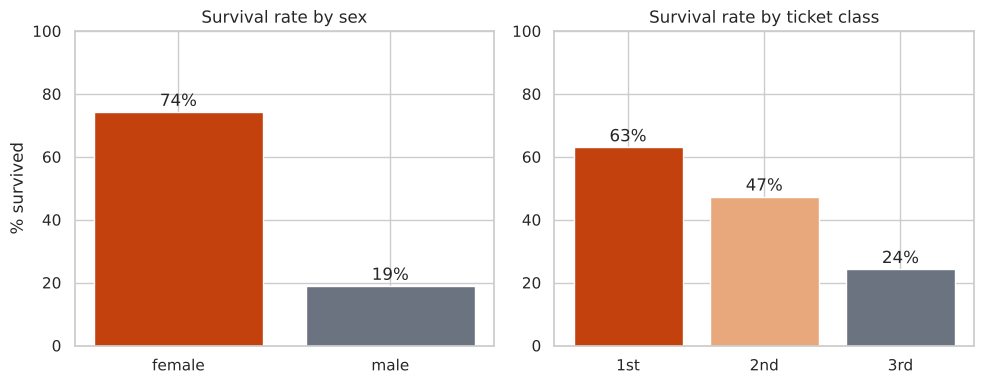

In [11]:
fig, ax = plt.subplots(1,2, figsize=(10,4))
g = d.groupby('sex', observed=True)['survived'].mean()*100
ax[0].bar(g.index.astype(str), g.values, color=[OR, GR]); ax[0].set(title='Survival rate by sex', ylabel='% survived', ylim=(0,100))
for i,v in enumerate(g.values): ax[0].text(i, v+2, f'{v:.0f}%', ha='center')
g = d.groupby('pclass', observed=True)['survived'].mean()*100
ax[1].bar(['1st','2nd','3rd'], g.values, color=[OR, '#E8A87C', GR]); ax[1].set(title='Survival rate by ticket class', ylim=(0,100))
for i,v in enumerate(g.values): ax[1].text(i, v+2, f'{v:.0f}%', ha='center')
plt.tight_layout(); plt.savefig('fig1_sex_class.png', dpi=150)

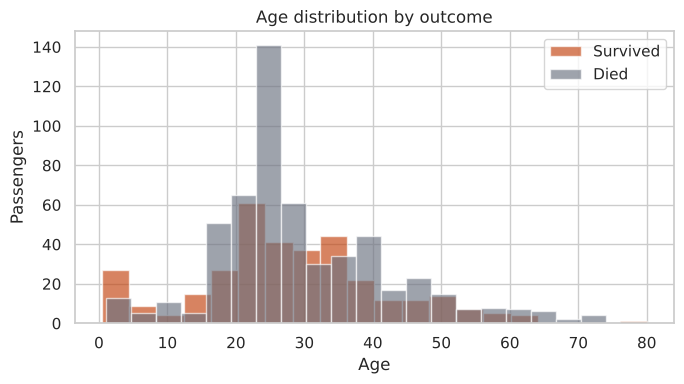

In [12]:
fig, ax = plt.subplots(figsize=(7,4))
for s,c,l in [(1,OR,'Survived'),(0,GR,'Died')]:
    ax.hist(d.loc[d.survived==s,'age'], bins=20, alpha=.65, color=c, label=l)
ax.set(title='Age distribution by outcome', xlabel='Age', ylabel='Passengers'); ax.legend()
plt.tight_layout(); plt.savefig('fig2_age_hist.png', dpi=150)

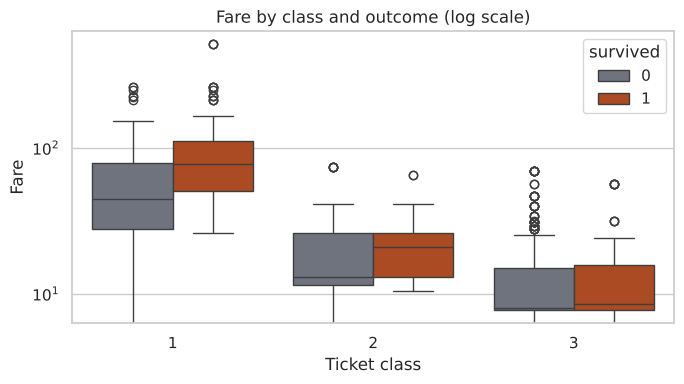

In [13]:
fig, ax = plt.subplots(figsize=(7,4))
sns.boxplot(data=d, x='pclass', y='fare', hue='survived', palette={0:GR,1:OR}, ax=ax)
ax.set_yscale('log'); ax.set(title='Fare by class and outcome (log scale)', xlabel='Ticket class', ylabel='Fare')
plt.tight_layout(); plt.savefig('fig3_fare_box.png', dpi=150)

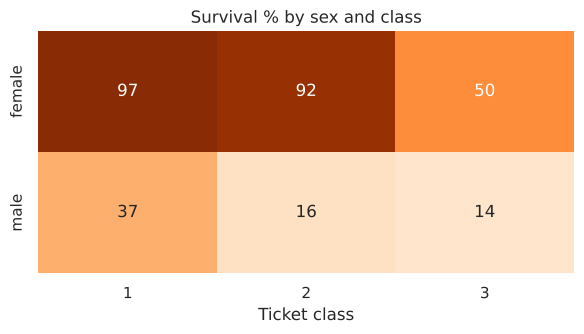

In [14]:
p = d.pivot_table(index='sex', columns='pclass', values='survived', aggfunc='mean', observed=True)*100
fig, ax = plt.subplots(figsize=(6,3.5))
sns.heatmap(p, annot=True, fmt='.0f', cmap='Oranges', cbar=False, ax=ax, vmin=0, vmax=100)
ax.set(title='Survival % by sex and class', xlabel='Ticket class', ylabel='')
plt.tight_layout(); plt.savefig('fig4_heatmap.png', dpi=150)

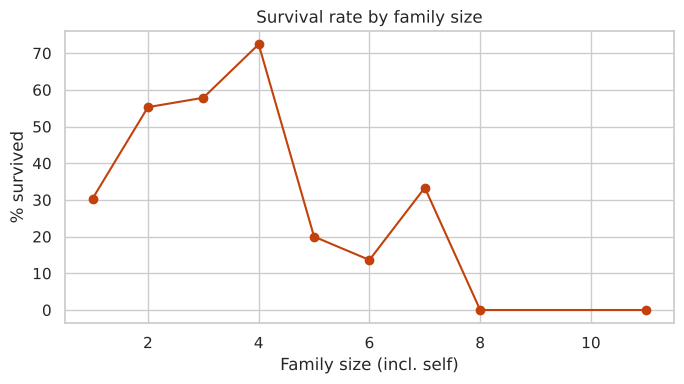

In [15]:
fig, ax = plt.subplots(figsize=(7,4))
fs = d.groupby('family_size')['survived'].mean()*100
ax.plot(fs.index, fs.values, marker='o', color=OR)
ax.set(title='Survival rate by family size', xlabel='Family size (incl. self)', ylabel='% survived')
plt.tight_layout(); plt.savefig('fig5_family.png', dpi=150)

## 5. Predictive check

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score
X = pd.get_dummies(d[['pclass','sex','age','family_size','log_fare']], drop_first=True).astype(float)
y = d['survived']
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=.2,random_state=0,stratify=y)
m = LogisticRegression(max_iter=1000).fit(Xtr,ytr)
print('Baseline (predict nobody survives):', round(1-yte.mean(),3))
print('Test accuracy:', round(accuracy_score(yte,m.predict(Xte)),3))
print('5-fold CV accuracy:', round(cross_val_score(LogisticRegression(max_iter=1000),X,y,cv=5).mean(),3))
print(dict(zip(X.columns, m.coef_[0].round(2))))

Baseline (predict nobody survives): 0.615
Test accuracy: 0.788
5-fold CV accuracy: 0.794
{'age': np.float64(-0.04), 'family_size': np.float64(-0.34), 'log_fare': np.float64(0.53), 'pclass_2': np.float64(-0.53), 'pclass_3': np.float64(-1.61), 'sex_male': np.float64(-2.59)}
